# Работа с данными: загрузка, очистка, визуализация

Работа начинается с исходного файла, а заканчивается проверенным набором записей и понятным представлением результата. Между этими этапами нужно установить формат, проверить содержимое полей, согласовать обозначения и объяснить судьбу записей, которые не прошли проверку.

В материале используется небольшой вымышленный журнал запросов к сервису ИИ за **1–7 октября 2026 года**. В него намеренно включены пробелы, разные названия одного вида содержимого, пропуски, неверные значения и повторы. Справочник JSON задаёт допустимые названия. Все исходные значения находятся внутри ноутбука; скачивание файлов не требуется.

Перед каждым блоком кода описана его цель, после кода и результатов разобраны использованные конструкции Python и команды библиотек. Примеры выполнены, таблицы и рисунки сохранены. Заданий и математической теории нет. При повторном выполнении ячейки запускаются сверху вниз в одном ядре Python.

Основные объекты NumPy, Pandas и Matplotlib разбирались в предыдущем файле. Здесь они применяются к единому процессу работы с данными; пояснения после кода позволяют читать примеры самостоятельно.

**Содержание**

- [1. Источники, файлы и правила данных](#sources)
- [2. Согласование записей и преобразование типов](#cleaning)
- [3. Проверки и объяснение результата очистки](#validation)
- [4. Визуализация проверенных данных](#visualization)
- [5. Сохранение и повторная загрузка](#export)

<a id="sources"></a>
## 1. Источники, файлы и правила данных

### 1.1. Организация воспроизводимого примера

**Исходные данные** сохраняются отдельно от **результатов обработки**. Это позволяет снова прочитать исходник и проверить решения программы. Полезно сохранять также причины отклонения записей, а не только удачный результат.

Внутри папки `04_данные` ноутбук создаёт две подпапки: `исходные` и `результат`. Первая содержит учебные CSV и JSON, вторая — очищенные данные, отчёты и изображения. Рабочая папка ядра определяет, где появится `04_данные`; при выполнении вместе с материалами курса это папка с ноутбуком.

Первый блок подключает средства работы с путями, JSON, таблицами и рисунками. Затем создаёт папки учебного примера, задаёт пути двух исходных файлов и границы периода выгрузки. Вывод показывает фактическое расположение данных в текущей среде.

In [1]:
%matplotlib inline

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.constrained_layout.use'] = True

data_dir = Path('04_данные')
source_dir = data_dir / 'исходные'
result_dir = data_dir / 'результат'
source_dir.mkdir(parents=True, exist_ok=True)
result_dir.mkdir(parents=True, exist_ok=True)

csv_path = source_dir / 'запросы.csv'
reference_path = source_dir / 'виды.json'
period_start = pd.Timestamp('2026-10-01')
period_end = pd.Timestamp('2026-10-07')

print('Папка учебных данных:', data_dir.resolve())

Папка учебных данных: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\04_данные


**Разбор кода.**

- `%matplotlib inline` — команда Jupyter для показа рисунков под ячейками. `import` подключает готовые средства. `as pd` и `as plt` дают библиотекам короткие имена. `from ... import ...` подключает отдельное имя: `Path` для путей, `display` для показа таблиц.
- Модуль `json` входит в стандартную библиотеку Python и работает с форматом JSON. Pandas и Matplotlib должны быть установлены в среде ядра. Подключение через `import` не устанавливает библиотеку.
- Строка в кавычках — текстовое значение. `plt.rcParams[...]` выбирает настройку рисунков по текстовому ключу. Знак `=` присваивает новое значение, `True` означает включённое логическое состояние. Выбранный шрифт поддерживает русские буквы, автоматическая компоновка размещает подписи.
- `Path('04_данные')` создаёт объект пути. Вызов записан с круглыми скобками; строка внутри — аргумент. Такой путь **относительный**, то есть начинается от рабочей папки ядра.
- В выражении `data_dir / 'исходные'` оператор `/` у объекта `Path` соединяет части пути. Он не читает содержимое папки. Новые пути сохраняются в переменных через `=`.
- `.mkdir(parents=True, exist_ok=True)` создаёт папку. `parents=True` разрешает создать необходимые родительские папки, `exist_ok=True` позволяет повторный вызов для уже существующей папки. Слева от `=` внутри вызова стоят имена параметров.
- `csv_path`, `reference_path` — пути файлов, а не сами загруженные таблицы. Расширения `.csv` и `.json` обозначают выбранные форматы. Создание объекта пути ещё не создаёт файл.
- `pd.Timestamp(...)` создаёт значение даты. В строке `2026-10-01` указан год, месяц, день; такой порядок используется здесь явно. `period_start`, `period_end` задают границы учебной выгрузки.
- `data_dir.resolve()` возвращает абсолютный путь, начинающийся от корня диска. Метод вызывается с пустыми скобками, атрибуты читаются без них. `print(...)` выводит подпись и путь через пробел.

Дальше пути используются по именам. Они не содержат жёстко записанного имени пользователя или диска, поэтому ноутбук может создать те же учебные папки в другой рабочей среде.

### 1.2. Формат файла и содержание поля

**CSV** — текстовая таблица: одна строка файла обычно соответствует записи, разделитель отделяет поля. В учебном CSV разделитель — точка с запятой, дробная часть времени записана через запятую. Значение с точкой с запятой внутри заключено в кавычки, чтобы не стать двумя полями.

**Кодировка** определяет, как буквы представлены в файле. Здесь используется UTF-8; вариант `utf-8-sig` добавляет служебную метку в начале CSV и удобен для ряда настольных программ. **JSON** хранит именованные поля и вложенные структуры; справочник записан списком объектов.

Разделитель полей, десятичный знак и кодировка — разные свойства. Неправильный выбор одного нельзя исправить случайной сменой другого.

Следующий блок создаёт маленькие учебные исходники: журнал с намеренными проблемами и справочник допустимых видов содержимого. Он записывает только два названных файла в учебной папке. Повторное выполнение восстанавливает их исходное содержимое, перезаписывая эти учебные файлы.

In [2]:
csv_text = """request_id;created_at;kind;status;file_count;elapsed_seconds;note
001;01.10.2026; Текст ;ГОТОВО;1;2,5;Первый запрос
002;01.10.2026;изображения;готово;3;6,0;
003;02.10.2026;AUDIO; В  РАБОТЕ ;2;;Запущено
004;02.10.2026;текст;ожидает;1;;
005;03.10.2026;image;done;4;8,2;"Проверено; вручную"
006;03.10.2026;текст;готово;два;3,4;Ошибка количества
007;31.02.2026;аудио;готово;1;4,0;Ошибка даты
008;04.10.2026;видео;готово;2;5,1;Новый вид
009;04.10.2026;текст;готово;2;;Нет времени
010;04.10.2026;текст;ожидает;0;;Ноль файлов
011;05.10.2026;Аудио;готово;2;4,7;
012;05.10.2026;текст;готово;1;-1,0;Отрицательное время
013;06.10.2026;TEXT;в работе;3;;
014;06.10.2026;текст;неизвестно;1;;Неизвестный статус
015;07.10.2026;текст;готово;2;3,8;Версия А
015;07.10.2026;текст;готово;4;7,6;Версия Б
016;07.10.2026;текст;в работе;1;быстро;Ошибка времени
002;01.10.2026;изображения;готово;3;6,0;
"""

kind_records = [
    {'kind_key': 'текст', 'kind_clean': 'Текст'},
    {'kind_key': 'text', 'kind_clean': 'Текст'},
    {'kind_key': 'изображение', 'kind_clean': 'Изображение'},
    {'kind_key': 'изображения', 'kind_clean': 'Изображение'},
    {'kind_key': 'image', 'kind_clean': 'Изображение'},
    {'kind_key': 'аудио', 'kind_clean': 'Аудио'},
    {'kind_key': 'audio', 'kind_clean': 'Аудио'},
]

csv_path.write_text(csv_text, encoding='utf-8-sig')
reference_path.write_text(
    json.dumps(kind_records, ensure_ascii=False, indent=2),
    encoding='utf-8',
)
print('Подготовлены:', csv_path.name, reference_path.name)

Подготовлены: запросы.csv виды.json


**Разбор кода.**

- `csv_text = """..."""` сохраняет многострочный текст. Тройные кавычки позволяют записать переносы строк непосредственно. Первая строка содержит названия полей, следующие — исходные записи. Они пока не являются DataFrame.
- `;` внутри этого текста — разделитель CSV, а не команда Python. Двойные кавычки вокруг `Проверено; вручную` относятся к CSV: чтение сохранит этот комментарий одним полем.
- Пустое место между разделителями, например `2;;Запущено`, означает пустое поле времени. Числа `001` внутри многострочного текста сохраняются как символы: Python не пытается интерпретировать их как числовые литералы.
- `kind_records = [...]` создаёт список. Каждый элемент `{...}` — словарь: ключ и значение разделены двоеточием, пары — запятыми. `kind_key` содержит вариант записи, `kind_clean` — согласованное название.
- `.write_text(текст, encoding=...)` — метод объекта `Path`, записывающий текст в файл. Вызов создаёт файл или заменяет его содержимое. Аргумент `encoding` явно задаёт кодировку. Пути определены в предыдущей ячейке.
- `json.dumps(...)` превращает список словарей в текст JSON. `ensure_ascii=False` сохраняет русские буквы в читаемом виде, `indent=2` добавляет отступы для удобства просмотра. Эти настройки меняют запись JSON, а не значения справочника.
- Внутренний вызов `json.dumps(...)` выполняется раньше внешнего `.write_text(...)`. Перенос внутри незакрытых скобок продолжает одну инструкцию. Запятая после последнего аргумента допустима.
- `.name` — атрибут пути, содержащий только имя файла. `print(...)` показывает два имени и подпись; он не выводит весь файл.

Создание исходников включено ради автономности материала. Следующие ячейки будут читать настоящие файлы с диска, а не напрямую брать данные из переменных `csv_text` и `kind_records`.

### 1.3. Чтение CSV с сохранением исходных значений

При первом чтении важно сохранить идентификаторы и проблемные записи. Если превратить `001` в число, ведущие нули исчезнут. Если заранее угадать все типы, ошибочное значение может остановить чтение ещё до осмотра файла.

Поэтому исходные поля читаются как текст. Пустая строка пока остаётся пустой строкой, а значение каждого поля преобразуется позже по отдельному правилу. В таблицу добавляется номер записи, позволяющий найти её источник после сортировки и разделения данных.

Этот блок читает журнал с явно заданными разделителем и кодировкой. Он сохраняет список исходных столбцов, добавляет порядковый номер записи и показывает начало таблицы, её форму и идентификаторы. Нумерация относится к записям после заголовка, а не к физическим строкам произвольного CSV.

In [3]:
raw = pd.read_csv(
    csv_path,
    sep=';', encoding='utf-8-sig',
    dtype='string', keep_default_na=False,
    on_bad_lines='error',
)
source_columns = raw.columns.tolist()
raw.insert(0, 'source_row', range(1, len(raw) + 1))

display(raw.head(6))
print('Форма:', raw.shape)
print('Первые идентификаторы:', raw['request_id'].head(3).tolist())

,source_row,request_id,created_at,kind,status,file_count,elapsed_seconds,note
0,1,001,01.10.2026,Текст,ГОТОВО,1,"2,5",Первый запрос
1,2,002,01.10.2026,изображения,готово,3,"6,0",
2,3,003,02.10.2026,AUDIO,В РАБОТЕ,2,,Запущено
3,4,004,02.10.2026,текст,ожидает,1,,
4,5,005,03.10.2026,image,done,4,"8,2",Проверено; вручную
5,6,006,03.10.2026,текст,готово,два,"3,4",Ошибка количества


Форма: (18, 8)
Первые идентификаторы: ['001', '002', '003']


**Разбор кода.**

- `pd.read_csv(csv_path, ...)` открывает файл и возвращает DataFrame. `sep=';'` задаёт разделитель, `encoding='utf-8-sig'` учитывает кодировку и служебную метку CSV.
- `dtype='string'` читает все исходные поля строковым типом Pandas. Кавычки важны: `'string'` — название типа для параметра. Идентификатор `'001'` сохраняется текстом, а не превращается в 1.
- `keep_default_na=False` отключает стандартное распознавание текстовых обозначений пропуска. Пустое исходное поле здесь остаётся строкой `''`; специальные значения пропуска будут введены осознанно позже.
- `on_bad_lines='error'` останавливает чтение при некоторых нарушениях структуры строки, например лишних полях. Этот параметр не проверяет смысл дат, статусов и чисел. Он также не означает полного контроля всех возможных дефектов файла.
- `raw.columns` получает имена полей. Метод `.tolist()` превращает их в обычный список. Список `source_columns` сохранён **до** добавления служебного столбца; он понадобится для сравнения исходного содержания записей.
- `.insert(0, 'source_row', ...)` вставляет столбец на позицию 0. Второй аргумент — имя, третий — значения. Этот метод меняет таблицу `raw` непосредственно, поэтому его результат не присваивается обратно.
- `len(raw)` — количество записей. В `range(1, len(raw) + 1)` правая граница не включается; прибавление 1 даёт номера от 1 до последней записи. Это нумерация происхождения, а индекс Pandas слева по-прежнему начинается с 0.
- `.head(6)` берёт первые шесть записей, `.shape` читает форму. `display(...)` показывает таблицу, `print(...)` — короткие сообщения. Последняя цепочка выбирает столбец, первые три его значения и превращает их в список.

Форма `(18, 8)` включает семь исходных полей и один служебный столбец. Номер записи будет сохраняться в отчёте, даже если запись не попадёт в очищенный набор.

Следующий блок читает справочник JSON как отдельную таблицу. Явно указано, что файл содержит список записей, а два его поля нужно хранить как текст. Полученная таблица будет определять допустимые соответствия названий.

In [4]:
kind_reference = pd.read_json(
    reference_path,
    orient='records', encoding='utf-8',
    dtype={'kind_key': 'string', 'kind_clean': 'string'},
)
display(kind_reference)

,kind_key,kind_clean
0,текст,Текст
1,text,Текст
2,изображение,Изображение
3,изображения,Изображение
4,image,Изображение
5,аудио,Аудио
6,audio,Аудио


**Разбор кода.**

- `pd.read_json(...)` читает JSON с диска и создаёт DataFrame. Первым аргументом передаётся путь `reference_path`, а не переменная с текстом или списком словарей.
- `orient='records'` описывает структуру файла: список объектов, каждый объект соответствует записи с именованными полями. Другие формы JSON требуют соответствующего описания структуры; расширение `.json` само по себе его не определяет.
- `encoding='utf-8'` задаёт кодировку текста. Справочник был записан именно в ней.
- `dtype={...}` передаёт словарь: ключ — столбец, значение — желаемый тип. Имена `kind_key`, `kind_clean` совпадают с именами внутри файла. Запятые разделяют пары словаря.
- Один знак `=` сохраняет результат в `kind_reference`. `display(kind_reference)` показывает все семь соответствий; пустые строки или переносы внутри скобок служат оформлению программы.

Один согласованный вид может иметь несколько исходных вариантов, но каждый исходный ключ должен иметь только одно определённое соответствие. Это условие проверяется до соединения данных.

### 1.4. Правила допустимой записи

Очистка опирается на смысл полей, а не на случайный набор команд удаления. Для этого примера действуют следующие правила.

| Поле | Правило |
|---|---|
| `request_id` | непустой текст; после разрешения повторов один запрос имеет одну запись |
| `created_at` | существующая дата в формате день.месяц.год, внутри периода 1–7 октября 2026 года |
| `kind` | после согласования должен находиться в справочнике |
| `status` | после согласования: «готово», «в работе» или «ожидает» |
| `file_count` | положительное целое количество; исходная запись содержит только цифры |
| `elapsed_seconds` | если значение указано, оно должно быть числом не меньше нуля; для готового запроса оно обязательно |
| `note` | необязательный текстовый комментарий |

Полное повторение исходной записи можно убрать, сохранив факт такого решения. Две различающиеся записи с одним идентификатором требуют разбора: в выгрузке нет времени обновления, позволяющего выбрать актуальную версию.

Этот блок проверяет наличие обязательных столбцов и однозначность справочника. Затем показывает число пока пустых строковых значений в каждом исходном поле. Такой обзор помогает увидеть пропуски, но решение о допустимости каждого пропуска принимается по правилам конкретного поля.

In [5]:
expected_columns = [
    'request_id', 'created_at', 'kind', 'status',
    'file_count', 'elapsed_seconds', 'note',
]
assert set(expected_columns).issubset(raw.columns), 'Не хватает обязательных столбцов'
assert kind_reference['kind_key'].is_unique, 'В справочнике повторяются ключи'
assert kind_reference[['kind_key', 'kind_clean']].notna().all().all(), 'Пропуск в справочнике'

empty_fields = raw[source_columns].eq('').sum()
display(empty_fields.rename('Пустые поля до очистки'))
print('Структура файлов соответствует правилам чтения.')

request_id         0
created_at         0
kind               0
status             0
file_count         0
elapsed_seconds    6
note               5
Name: Пустые поля до очистки, dtype: Int64

Структура файлов соответствует правилам чтения.


**Разбор кода.**

- `expected_columns = [...]` создаёт список обязательных имён. `set(...)` превращает его во множество — набор без повторений. Метод `.issubset(raw.columns)` проверяет, присутствуют ли все обязательные имена среди столбцов. Порядок здесь не проверяется, дополнительные поля не запрещаются.
- `assert условие, 'сообщение'` — исполняемая проверка. Если условие ложно, выполнение останавливается с указанным сообщением. Это защита от продолжения обработки неподходящей структуры, а не задание читателю.
- `kind_reference['kind_key'].is_unique` — логический атрибут Series, показывающий отсутствие повторяющихся ключей. Он читается без круглых скобок.
- `[['kind_key', 'kind_clean']]` выбирает таблицу двух полей. `.notna()` отмечает заполненные значения. Первый `.all()` проверяет каждый столбец, второй — все полученные результаты, возвращая одно логическое значение.
- `raw[source_columns]` выбирает только исходные поля, без служебного номера. `.eq('')` поэлементно сравнивает их с пустой строкой. Метод `.sum()` по умолчанию считает значения `True` по каждому столбцу, поэтому получается количество пустых полей.
- `.rename('Пустые поля до очистки')` задаёт имя полученной Series для вывода. Это не переименование исходных столбцов. `display(...)` показывает обзор, `print(...)` сообщает о пройденных проверках.

Пустое время у ожидающего запроса и пустое время у готового запроса выглядят одинаково, но имеют разный смысл. Удаление всех строк с любым пропуском потеряло бы допустимые записи.

<a id="cleaning"></a>
## 2. Согласование записей и преобразование типов

### 2.1. Полные повторы исходных записей

**Полный повтор** означает совпадение всех исходных полей. Служебный номер записи в сравнение не входит: иначе каждая строка выглядела бы уникальной только из-за добавленной нумерации.

Оставляется первое появление полного набора полей. Остальные повторения сохраняются отдельно как объяснимо исключённые записи. Этот шаг ещё не решает проблему разных записей с одним идентификатором.

Следующий блок находит полные повторы по исходным столбцам. Он разделяет журнал на повторные экземпляры и записи, оставшиеся для обработки, затем показывает найденный повтор и количество записей в обеих частях.

In [6]:
exact_mask = raw.duplicated(subset=source_columns, keep='first')
exact_duplicates = raw.loc[exact_mask].copy()
unique_rows = raw.loc[~exact_mask].copy()

display(exact_duplicates)
print('Полных повторов:', len(exact_duplicates))
print('Записей для дальнейшей обработки:', len(unique_rows))

,source_row,request_id,created_at,kind,status,file_count,elapsed_seconds,note
17,18,002,01.10.2026,изображения,готово,3,"6,0",


Полных повторов: 1
Записей для дальнейшей обработки: 17


**Разбор кода.**

- `raw.duplicated(...)` возвращает логическую Series: `True` у экземпляров, которые считаются повторными. `subset=source_columns` ограничивает сравнение сохранённым списком исходных полей.
- `keep='first'` оставляет первое появление набора значений непомеченным. Последующие совпадения получают `True`. Здесь не используется только поле `request_id`: сравниваются все исходные поля.
- `.loc[exact_mask]` выбирает строки с `True`. В `.loc[~exact_mask]` знак `~` переворачивает логическую маску и выбирает остальные строки. Это поэлементная операция над маской, а не символ приблизительного значения.
- `.copy()` создаёт отдельные таблицы для дальнейшей работы. Исходный `raw` остаётся доступен со всеми записями и служебными номерами.
- `display(...)` показывает повторный экземпляр. `len(...)` считает строки соответствующей таблицы, `print(...)` выводит подпись и результат счёта.

Повторная запись 002 исключена из дальнейшей обработки, первое её появление сохранено. В результате остаётся 17 записей; ни одна исходная запись пока не потеряла своего номера происхождения.

### 2.2. Технические различия текстовых значений

Пробелы по краям, регистр букв и повторяющиеся пробелы могут создавать разные строки для одного смысла. Их устранение — техническое согласование записи. Перевод `image` в «Изображение» — уже содержательное соответствие, которое должно быть задано справочником.

Необязательный пустой комментарий переводится в явный пропуск Pandas. Обязательные поля пока не заполняются придуманными значениями.

Этот блок создаёт рабочую копию записей, убирает крайние пробелы во всех исходных текстовых полях и готовит отдельные ключи вида и статуса. В ключе статуса несколько подряд идущих пробельных символов заменяются одним пробелом; исходный журнал при этом остаётся отдельной таблицей.

In [7]:
normalized = unique_rows.copy()
for column in source_columns:
    normalized[column] = normalized[column].str.strip()

normalized['kind_key'] = normalized['kind'].str.lower()
normalized['status_key'] = (
    normalized['status'].str.lower().str.replace(r'\s+', ' ', regex=True)
)
normalized['note'] = normalized['note'].replace('', pd.NA)

display(normalized[['request_id', 'kind', 'kind_key', 'status', 'status_key']].head(5))

,request_id,kind,kind_key,status,status_key
0,001,Текст,текст,ГОТОВО,готово
1,002,изображения,изображения,готово,готово
2,003,AUDIO,audio,В РАБОТЕ,в работе
3,004,текст,текст,ожидает,ожидает
4,005,image,image,done,done


**Разбор кода.**

- `unique_rows.copy()` создаёт рабочую таблицу. `for column in source_columns:` последовательно берёт каждое имя исходного столбца. Строка с четырьмя пробелами отступа выполняется для каждого имени; после возврата к левому краю цикл закончен.
- `normalized[column]` выбирает столбец по значению переменной `column`. Кавычки вокруг `column` дали бы буквальное имя «column», поэтому здесь их нет.
- `.str` — доступ к поэлементным текстовым действиям Series. `.str.strip()` убирает пробельные символы по краям каждой строки. Присваивание слева записывает полученные значения обратно в текущий столбец рабочей таблицы.
- Служебный числовой `source_row` не входит в `source_columns`, поэтому текстовый метод к нему не применяется.
- `.str.lower()` переводит буквы в нижний регистр. Новые поля `kind_key`, `status_key` содержат ключи для сопоставления; исходные названия `kind`, `status` остаются отдельными столбцами.
- `.str.replace(r'\s+', ' ', regex=True)` использует **регулярное выражение**, шаблон поиска. `\s` обозначает пробельный символ, `+` — одно или несколько повторений. Найденная последовательность заменяется одной строкой-пробелом `' '`.
- Буква `r` перед кавычкой сохраняет обратную косую черту в шаблоне. `regex=True` включает интерпретацию шаблона. Например, `В  РАБОТЕ` после двух операций становится `в работе`.
- `.replace('', pd.NA)` заменяет пустую строку в комментариях специальным значением пропуска. `pd.NA` — пропуск Pandas, а не текст `'NA'` и не число 0. У этого метода здесь нет `.str`, потому что заменяются целые значения поля.
- Внутренний список у `[[...]]` выбирает пять столбцов. `.head(5)` ограничивает просмотр пятью строками, `display(...)` показывает результат. Скобки вокруг многострочного выражения продолжают одну инструкцию.

Подготовленные ключи ещё не являются окончательными категориями: например, `image` остаётся `image` до применения справочника.

Следующий блок задаёт допустимые соответствия статусов и применяет их к подготовленному текстовому ключу. Он показывает различные сочетания исходного статуса, ключа и согласованного результата; незнакомый статус остаётся без соответствия для последующей проверки.

In [8]:
status_aliases = {
    'готово': 'готово',
    'done': 'готово',
    'в работе': 'в работе',
    'ожидает': 'ожидает',
}
normalized['status_clean'] = normalized['status_key'].map(status_aliases).astype('string')
display(normalized[['status', 'status_key', 'status_clean']].drop_duplicates())

,status,status_key,status_clean
0,ГОТОВО,готово,готово
1,готово,готово,готово
2,В РАБОТЕ,в работе,в работе
3,ожидает,ожидает,ожидает
4,done,done,готово
12,в работе,в работе,в работе
13,неизвестно,неизвестно,<NA>


**Разбор кода.**

- `status_aliases = {...}` создаёт словарь соответствий. Ключ слева от двоеточия — распознанная запись статуса, значение справа — согласованное название. Запятые разделяют пары.
- `normalized['status_key']` выбирает Series подготовленных ключей. `.map(status_aliases)` ищет каждый ключ в словаре и подставляет соответствующее значение.
- Для `done` задано конкретное соответствие «готово». Для `неизвестно` соответствия нет, поэтому получается пропуск, а не случайный статус по умолчанию.
- `.astype('string')` приводит результат к строковому типу Pandas, поддерживающему пропуски. Префикс `pd.` при названии типа в строке не нужен: параметр получает текстовое имя типа.
- `normalized['status_clean'] = ...` добавляет новый столбец. Правая часть вычисляется до присваивания. Старые поля статуса остаются рядом, чтобы видеть происхождение результата.
- `.drop_duplicates()` у выбранной таблицы убирает повторяющиеся сочетания только **в представлении для вывода**. Результат передаётся в `display(...)`; сама таблица `normalized` этим вызовом не переназначается.

Список разрешённых статусов — правило этого учебного сервиса. Автоматически считать любое похожее слово известным статусом оснований нет.

Этот блок присоединяет согласованное название вида из JSON-справочника по подготовленному ключу. Сохраняются все обрабатываемые записи, включая неизвестный вид «видео». Дополнительное поле показывает, нашлось ли соответствие в справочнике.

In [9]:
enriched = normalized.merge(
    kind_reference,
    on='kind_key', how='left',
    validate='many_to_one', indicator='kind_lookup',
)
display(enriched[['request_id', 'kind_key', 'kind_clean', 'kind_lookup']])
print('Не найдено в справочнике:', enriched['kind_clean'].isna().sum())

,request_id,kind_key,kind_clean,kind_lookup
0,001,текст,Текст,both
1,002,изображения,Изображение,both
2,003,audio,Аудио,both
3,004,текст,Текст,both
4,005,image,Изображение,both
5,006,текст,Текст,both
6,007,аудио,Аудио,both
7,008,видео,<NA>,left_only
8,009,текст,Текст,both
9,010,текст,Текст,both


Не найдено в справочнике: 1


**Разбор кода.**

- `normalized.merge(kind_reference, ...)` соединяет две таблицы. Таблица слева — рабочие записи, первый аргумент справа — справочник. `on='kind_key'` задаёт общий ключ сопоставления.
- `how='left'` сохраняет все строки левой таблицы. Если ключ не найден справа, новые поля получают пропуск. Такой способ позволяет увидеть проблему, а не незаметно потерять запись при соединении.
- `validate='many_to_one'` требует, чтобы одному ключу справочника соответствовала не более чем одна его строка. Много записей журнала могут использовать этот ключ, но справочник не должен размножать их несколькими совпадениями.
- `indicator='kind_lookup'` добавляет поле происхождения совпадения с выбранным именем. Значение `both` означает, что ключ найден в обеих таблицах, `left_only` — только в журнале.
- Согласованное название сохраняется в добавленном `kind_clean`. Результат соединения присваивается `enriched`, исходный `normalized` остаётся доступен отдельно.
- `display(...)` показывает нужные четыре столбца. В `print(...)` метод `.isna()` отмечает пропуски, `.sum()` считает их. Эти вызовы отвечают на вопрос о ненайденных соответствиях.

У «видео» нет разрешённого соответствия. Строка сохранена с пропуском в `kind_clean` и дальше получит объяснение причины отклонения.

### 2.3. Даты: заданный формат и невозможные значения

Текст `01.10.2026` нужно преобразовать в дату, чтобы проверять период и упорядочивать записи по календарю. Формат задаётся явно: так порядок дня и месяца не зависит от предположений программы.

Невозможная дата превращается в специальный пропуск даты `NaT`. Это позволяет собрать отчёт о проблемах, а не остановиться на первой неверной записи. Само преобразование ещё не означает, что такая строка допустима.

Следующий блок создаёт рабочую таблицу с разобранной датой и показывает записи, дату которых распознать не удалось. В примере это несуществующий день февраля. Исходный текст даты сохраняется рядом с новым значением для проверки причины.

In [10]:
parsed = enriched.copy()
parsed['created_at_value'] = pd.to_datetime(
    parsed['created_at'], format='%d.%m.%Y', errors='coerce',
)
bad_date_mask = parsed['created_at_value'].isna()
display(parsed.loc[bad_date_mask, ['source_row', 'request_id', 'created_at', 'created_at_value']])
print('Тип разобранной даты:', parsed['created_at_value'].dtype)

,source_row,request_id,created_at,created_at_value
6,7,007,31.02.2026,NaT


Тип разобранной даты: datetime64[ns]


**Разбор кода.**

- `enriched.copy()` создаёт следующую рабочую таблицу `parsed`. Новый столбец `created_at_value` содержит преобразованные значения, а `created_at` пока остаётся исходным текстом.
- `pd.to_datetime(...)` преобразует Series в даты. Параметр `format='%d.%m.%Y'` задаёт шаблон: `%d` — день, `%m` — месяц, `%Y` — четырёхзначный год, точки — разделители. Символ `%` внутри строки формата не является командой Jupyter.
- `errors='coerce'` превращает непереводимые значения в `NaT`, пропуск для даты. Это выбранный способ **зафиксировать ошибку**, а не исправить дату вымышленным днём.
- `.isna()` создаёт маску пропусков. `.loc[bad_date_mask, [...]]` оставляет соответствующие записи и четыре поля, нужных для объяснения. В части после запятой передан список имён столбцов.
- `display(...)` показывает проблемную запись. `.dtype` читает тип хранения результата; `print(...)` выводит его вместе с подписью. В типе `datetime64[ns]` обозначено хранение даты и времени; для наших значений время суток не задавалось отдельно.

Вместо 31 февраля не подставляется ни конец февраля, ни текущая дата. Строка остаётся доступной для дальнейшего отчёта с исходным ошибочным текстом.

### 2.4. Числовые поля и осознанные пропуски

Количество файлов допускает только запись целого числа цифрами. Время обработки может содержать дробную часть; десятичная запятая приводится к формату чтения числа. Эти поля преобразуются разными правилами.

Типы Pandas `Int64` и `Float64` с заглавной буквы поддерживают явный пропуск `pd.NA`. Это позволяет временно хранить нераспознанное значение рядом с корректными данными, а затем принять решение по правилам.

Этот блок проверяет текстовую форму количества файлов и преобразует допустимые записи в целый тип. Для времени он заменяет десятичную запятую точкой и выполняет отдельное преобразование. В выводе собраны характерные случаи: допустимый пропуск, текст вместо числа, ноль и отрицательное время.

In [11]:
integer_text_mask = parsed['file_count'].str.fullmatch(r'[0-9]+', na=False)
count_text = parsed['file_count'].where(integer_text_mask)
parsed['file_count_value'] = pd.to_numeric(count_text, errors='coerce').astype('Int64')

duration_text = parsed['elapsed_seconds'].str.replace(',', '.', regex=False)
parsed['elapsed_seconds_value'] = pd.to_numeric(duration_text, errors='coerce').astype('Float64')

examples_mask = parsed['request_id'].isin(['003', '006', '009', '010', '012', '016'])
display(parsed.loc[examples_mask, [
    'request_id', 'file_count', 'file_count_value', 'elapsed_seconds', 'elapsed_seconds_value',
]])

,request_id,file_count,file_count_value,elapsed_seconds,elapsed_seconds_value
2,003,2,2,,<NA>
5,006,два,<NA>,"3,4",3.4
8,009,2,2,,<NA>
9,010,0,0,,<NA>
11,012,1,1,"-1,0",-1.0
16,016,1,1,быстро,<NA>


**Разбор кода.**

- `.str.fullmatch(r'[0-9]+', na=False)` проверяет **всю** строку количества. В шаблоне `[0-9]` означает любую цифру от 0 до 9, `+` — одну или несколько цифр подряд. Буква `r` сохраняет текст шаблона; `na=False` считает пропуск не прошедшим такую проверку.
- `where(integer_text_mask)` сохраняет исходный текст в позициях с `True`, а в остальных помещает пропуск. Поэтому слово `два`, знак минуса или дробная запись не выдаются за подходящую текстовую форму целого количества.
- `pd.to_numeric(..., errors='coerce')` переводит распознаваемые значения в числа, остальные — в пропуски. `.astype('Int64')` явно задаёт целый тип Pandas с поддержкой пропусков. Заглавная `I` — часть имени этого типа.
- `.str.replace(',', '.', regex=False)` заменяет буквальную запятую точкой. `regex=False` отключает шаблоны поиска: здесь меняется конкретный символ, а не регулярное выражение.
- Для времени `.astype('Float64')` выбирает дробный тип Pandas с пропусками. Заглавная `F` отличает это имя от некоторых других числовых типов. Пустое поле и нераспознанное слово оба дают пропуск результата, но их исходные строки различимы.
- Число 0 и отрицательное время **могут быть распознаны как числа**, поэтому преобразование само по себе их не отклоняет. Допустимость проверяется следующим отдельным этапом.
- `.isin([...])` выбирает шесть идентификаторов для просмотра. В `.loc[examples_mask, [...]]` логическая Series выбирает строки, список имён — столбцы. `display(...)` показывает исходный текст и результат рядом.

Время у «в работе» может быть ещё неизвестно, а слово «быстро» в непустом числовом поле является ошибкой. После преобразования важно сохранить это различие с помощью исходного текста.

### 2.5. Конфликтующие записи одного запроса

После удаления полных повторов один идентификатор всё ещё может встречаться несколько раз с разными данными. В нашем примере у 015 различаются количество файлов, время и комментарий. Ни первая, ни последняя позиция в файле сама по себе не доказывает актуальность записи.

Правило этого материала — отделить все версии конфликтующего запроса для разбора. Это решение сохраняет неопределённость видимой и не подменяет её догадкой.

Следующий блок находит все повторяющиеся непустые идентификаторы в уже разобранных записях. Конфликтующие версии сохраняются отдельно, остальные переходят к проверке полей. Вывод показывает обе версии 015 с номерами их исходных записей.

In [12]:
conflict_mask = (
    parsed.duplicated(subset='request_id', keep=False)
    & parsed['request_id'].ne('')
)
conflicts = parsed.loc[conflict_mask].copy()
candidates = parsed.loc[~conflict_mask].copy()

display(conflicts[['source_row', 'request_id', 'file_count', 'elapsed_seconds', 'note']])
print('Записей с конфликтом идентификатора:', len(conflicts))
print('Кандидатов для проверки полей:', len(candidates))

,source_row,request_id,file_count,elapsed_seconds,note
14,15,015,2,"3,8",Версия А
15,16,015,4,"7,6",Версия Б


Записей с конфликтом идентификатора: 2
Кандидатов для проверки полей: 15


**Разбор кода.**

- `parsed.duplicated(subset='request_id', keep=False)` сравнивает только идентификатор. `keep=False` помечает **все** записи повторяющегося идентификатора, включая первое появление. Это отличается от `keep='first'` при полном повторе.
- `.ne('')` означает поэлементное «не равно пустой строке». Условие не относит пустые идентификаторы к конфликтам: они получат отдельную причину некорректности поля.
- Символ `&` объединяет две логические Series поэлементно. Круглые скобки вокруг многострочной записи продолжают одно выражение, а не создают дополнительную таблицу.
- `.loc[conflict_mask]` выбирает конфликтующие версии. `.loc[~conflict_mask]` использует обратную маску. Метод `.copy()` делает отдельные таблицы для этих двух ветвей.
- `display(...)` показывает поля, по которым видны различия. `len(...)` считает записи каждой ветви, `print(...)` сопровождает числа подписями.

Две конфликтующие версии исключены из кандидатов, но сохранены в `conflicts`. Для проверки полей остаётся 15 записей; ни одна из версий 015 не объявлена актуальной без основания.

<a id="validation"></a>
## 3. Проверки и объяснение результата очистки

### 3.1. Одно правило — один признак нарушения

После преобразования типов проверяется допустимость значений. Для каждого правила создаётся столбец: `True` означает нарушение, `False` — отсутствие нарушения. У одной записи может быть несколько причин, поэтому число нарушений не обязано совпадать с числом отклонённых записей.

Проверки времени разделены: непустой нечисловой текст, отрицательное число и отсутствие обязательного результата — разные проблемы. Пустое время у ожидающего или выполняющегося запроса допустимо.

Следующий блок создаёт таблицу признаков нарушений по правилам журнала. Он явно учитывает пропуски после преобразования и границы периода. Вывод содержит количество нарушений каждого правила; неизвестный результат самой проверки останавливает обработку.

In [13]:
checks = pd.DataFrame(index=candidates.index)
checks['Пустой идентификатор'] = candidates['request_id'].eq('')
checks['Некорректная дата'] = candidates['created_at_value'].isna()
checks['Дата вне периода'] = (
    candidates['created_at_value'].notna()
    & ~candidates['created_at_value'].between(period_start, period_end)
)
checks['Неизвестный вид'] = candidates['kind_clean'].isna()
checks['Неизвестный статус'] = candidates['status_clean'].isna()
checks['Некорректное количество'] = (
    candidates['file_count_value'].isna()
    | candidates['file_count_value'].le(0).fillna(False)
)
checks['Нечисловое время'] = (
    candidates['elapsed_seconds'].ne('')
    & candidates['elapsed_seconds_value'].isna()
)
checks['Отрицательное время'] = candidates['elapsed_seconds_value'].lt(0).fillna(False)
checks['Нет времени готового запроса'] = (
    candidates['status_clean'].eq('готово').fillna(False)
    & candidates['elapsed_seconds_value'].isna()
)

assert checks.notna().all().all(), 'Есть неопределённый результат проверки'
checks = checks.astype(bool)
display(checks.sum().rename('Нарушений'))

Пустой идентификатор            0
Некорректная дата               1
Дата вне периода                0
Неизвестный вид                 1
Неизвестный статус              1
Некорректное количество         2
Нечисловое время                1
Отрицательное время             1
Нет времени готового запроса    1
Name: Нарушений, dtype: int64

**Разбор кода.**

- `pd.DataFrame(index=candidates.index)` создаёт таблицу с теми же подписями строк, что у кандидатов. Благодаря этому результаты правил относятся к нужным записям даже после исключения части строк.
- Каждое `checks['...'] = ...` добавляет один именованный столбец. Его имя одновременно будет понятным текстом причины для отчёта.
- `.eq('')` проверяет пустой идентификатор, `.isna()` — пропуск, `.notna()` — заполненность. Это поэлементные проверки Series, возвращающие логические значения.
- `.between(period_start, period_end)` проверяет попадание даты в период, включая обе границы по умолчанию. Знак `~` меняет результат на противоположный. Дополнительное `.notna()` не даёт назвать отсутствующую дату просто датой вне периода: у неё уже есть отдельная причина.
- `.le(0)` означает «меньше или равно нулю», `.lt(0)` — «меньше нуля». Они используются для количества и времени соответственно. `.fillna(False)` в этих сравнениях задаёт результат для неизвестного числа; отсутствие количества уже отдельно отмечено через `.isna()`.
- Символ `|` объединяет условия как поэлементное «или»: количество отсутствует **или** неположительно. Символ `&` означает поэлементное «и». Обычные слова `or`, `and` для таких Series не заменяют эти операции.
- Для «Нечислового времени» метод `.ne('')` отмечает непустой исходный текст. Он объединяется с проверкой пропуска после преобразования. Поэтому пустое необязательное время не попадает в эту причину.
- Для «Нет времени готового запроса» требуется согласованный статус «готово» и отсутствующее время. `.fillna(False)` у сравнения статуса не объявляет неизвестный статус готовым: неизвестность уже зафиксирована своим правилом.
- `assert checks.notna().all().all()` требует, чтобы сами результаты правил были определены: `.notna()` проверяет заполненность, первый `.all()` — каждый столбец, второй `.all()` — все столбцы вместе. После этого `.astype(bool)` задаёт обычный логический тип без пропусков. `bool` передан как имя типа Python, без кавычек.
- `.sum()` считает значения `True` в каждом столбце. `.rename(...)` задаёт имя итоговой Series, `display(...)` показывает её. Правило с нулём нарушений тоже остаётся в отчёте.

Таблица правил хранит объяснения до отделения плохих строк. Программа может показать все обнаруженные причины, а не только первую найденную ошибку.

Этот блок собирает названия нарушенных правил в понятное сообщение для каждой записи. Записи с хотя бы одной причиной отделяются в таблицу ошибок. В выводе остаются номер происхождения, идентификатор и текст причины, чтобы результат можно было проверить вручную.

In [14]:
def collect_reasons(row):
    active_names = row.index[row]
    return '; '.join(active_names)

invalid_mask = checks.any(axis=1)
reasons = checks.apply(collect_reasons, axis=1)
failed_rows = candidates.loc[invalid_mask].copy()
failed_rows['reason'] = reasons.loc[invalid_mask]

display(failed_rows[['source_row', 'request_id', 'reason']])

,source_row,request_id,reason
5,6,006,Некорректное количество
6,7,007,Некорректная дата
7,8,008,Неизвестный вид
8,9,009,Нет времени готового запроса
9,10,010,Некорректное количество
11,12,012,Отрицательное время
13,14,014,Неизвестный статус
16,17,016,Нечисловое время


**Разбор кода.**

- `def collect_reasons(row):` определяет функцию. Параметр `row` обозначает одну строку таблицы проверок. Тело функции выделено отступом.
- У этой строки `.index` содержит названия правил, а значения — логические признаки нарушения. `row.index[row]` использует признаки как маску и оставляет только названия с `True`.
- `'; '.join(active_names)` соединяет текстовые названия в одну строку через точку с запятой и пробел. `join` — метод строки-разделителя. Если нарушений нет, получается пустая строка.
- `return` передаёт собранный текст вызывающему коду. Он сам не печатает результат.
- `checks.any(axis=1)` проверяет каждую строку: есть ли хотя бы одно `True`. Число `1` здесь обозначает обработку по столбцам внутри строки. Полученная маска отмечает записи с нарушениями.
- `.apply(collect_reasons, axis=1)` вызывает нашу функцию для каждой строки. Имя функции передаётся **без** скобок: запускать её с очередной строкой будет Pandas. `.apply(...)` возвращает Series текстовых причин с теми же подписями строк.
- `.loc[invalid_mask].copy()` выбирает записи с нарушениями и создаёт отдельную таблицу. Присваивание `failed_rows['reason'] = ...` добавляет причины, выбранные той же маской из Series `reasons`.
- `display(...)` показывает три выбранных поля. Имена `source_row`, `request_id`, `reason` означают номер исходной записи, идентификатор и объяснение.

В этом наборе восемь записей получили ошибки полей. Даже при нескольких нарушениях у одной записи она оставалась бы одной строкой с несколькими перечисленными причинами.

### 3.2. Допустимые пропуски и окончательная таблица

Заполнение пропуска допустимо, когда оно не приписывает данным неизвестный факт. Для комментария выбран текст «Без комментария». Для времени выполняющегося или ожидающего запроса сохраняется пропуск: он означает отсутствие готового измерения и не равен нулевому времени.

В окончательную таблицу входят согласованные поля без промежуточных ключей и диагностических столбцов. История решений сохраняется отдельным отчётом, поэтому упрощение рабочего набора не уничтожает происхождение исключённых записей.

Следующий блок выбирает только прошедшие проверку записи, заполняет необязательный комментарий и собирает окончательные поля. Понятные исходные имена возвращаются уже преобразованным столбцам; затем задаются типы, календарный порядок и новый последовательный индекс.

In [15]:
accepted = candidates.loc[~invalid_mask].copy()
accepted['note'] = accepted['note'].fillna('Без комментария')

clean_data = accepted[[
    'request_id', 'created_at_value', 'kind_clean', 'status_clean',
    'file_count_value', 'elapsed_seconds_value', 'note',
]].rename(columns={
    'created_at_value': 'created_at',
    'kind_clean': 'kind',
    'status_clean': 'status',
    'file_count_value': 'file_count',
    'elapsed_seconds_value': 'elapsed_seconds',
})
clean_data = clean_data.astype({
    'request_id': 'string', 'kind': 'string', 'status': 'string',
    'file_count': 'Int64', 'elapsed_seconds': 'Float64', 'note': 'string',
})
clean_data = clean_data.sort_values(['created_at', 'request_id']).reset_index(drop=True)
display(clean_data)

,request_id,created_at,kind,status,file_count,elapsed_seconds,note
0,001,2026-10-01,Текст,готово,1,2.5,Первый запрос
1,002,2026-10-01,Изображение,готово,3,6.0,Без комментария
2,003,2026-10-02,Аудио,в работе,2,<NA>,Запущено
3,004,2026-10-02,Текст,ожидает,1,<NA>,Без комментария
4,005,2026-10-03,Изображение,готово,4,8.2,Проверено; вручную
5,011,2026-10-05,Аудио,готово,2,4.7,Без комментария
6,013,2026-10-06,Текст,в работе,3,<NA>,Без комментария


**Разбор кода.**

- `~invalid_mask` выбирает обратную сторону маски: записи без нарушений. `.copy()` создаёт таблицу `accepted`, которую дальше можно редактировать отдельно.
- `.fillna('Без комментария')` заменяет пропуск только в выбранном необязательном поле. Остальные поля этим вызовом не затрагиваются. Пустое время не подменяется числом.
- Двойные квадратные скобки выбирают список окончательных столбцов. Порядок списка определяет их порядок в результате.
- `.rename(columns={...})` получает словарь переименования: старое имя слева от двоеточия, новое справа. Например, разобранная дата `created_at_value` становится полем `created_at`. Это уже значение даты, а не прежний текст.
- `.astype({...})` получает другой словарь: имя поля и тип его хранения. `'string'`, `'Int64'`, `'Float64'` — имена типов Pandas. Тип даты здесь не меняется, поскольку она уже преобразована отдельно.
- `.sort_values(['created_at', 'request_id'])` сортирует сначала по дате, затем по идентификатору внутри даты. `.reset_index(drop=True)` создаёт последовательный индекс и не добавляет старый индекс отдельным полем.
- Цепочка методов возвращает новый результат, который присваивается `clean_data`. `display(...)` показывает окончательную таблицу из семи записей.

Ожидающий запрос 004 и выполняющиеся 003, 013 сохранены без времени. Они соответствуют правилам, хотя общее удаление всех пропусков исключило бы их.

### 3.3. Судьба каждой исходной записи

Отчёт обработки должен отвечать на вопрос: что произошло с конкретной исходной записью? Возможны четыре исхода: запись принята, признана полным повтором, требует разбора конфликта идентификатора или имеет ошибки полей.

Отдельная таблица для разбора должна содержать исходный текст значений. Это позволяет человеку проверить причину и подготовить исправленный источник. Автоматическая очистка не объявляет такое исправление выполненным.

Следующий блок собирает единый отчёт по четырём ветвям обработки. Для каждой исходной записи он сохраняет её номер, идентификатор, решение и причину, затем возвращает исходный порядок. По таблице можно найти результат любой из 18 записей.

In [16]:
accepted_audit = accepted[['source_row', 'request_id']].assign(
    decision='Принято', reason='',
)
duplicate_audit = exact_duplicates[['source_row', 'request_id']].assign(
    decision='Полный повтор', reason='Оставлено первое полное совпадение',
)
conflict_audit = conflicts[['source_row', 'request_id']].assign(
    decision='Конфликт ID', reason='Несколько различающихся записей одного запроса',
)
failed_audit = failed_rows[['source_row', 'request_id', 'reason']].assign(
    decision='Ошибка полей',
)

audit = pd.concat([
    accepted_audit, duplicate_audit, conflict_audit, failed_audit,
], ignore_index=True)
audit = audit[['source_row', 'request_id', 'decision', 'reason']]
audit = audit.sort_values('source_row').reset_index(drop=True)
display(audit)

,source_row,request_id,decision,reason
0,1,001,Принято,
1,2,002,Принято,
2,3,003,Принято,
3,4,004,Принято,
4,5,005,Принято,
5,6,006,Ошибка полей,Некорректное количество
6,7,007,Ошибка полей,Некорректная дата
7,8,008,Ошибка полей,Неизвестный вид
8,9,009,Ошибка полей,Нет времени готового запроса
9,10,010,Ошибка полей,Некорректное количество


**Разбор кода.**

- `[['source_row', 'request_id']]` выбирает два поля для основы каждого отчёта. `.assign(decision=..., reason=...)` возвращает таблицу с добавленными столбцами. Слева внутри вызова — имена новых полей, справа — значения.
- Одно строковое значение в `.assign(...)` записывается во все строки этой части. Для принятых записей причина пустая, для полного повтора и конфликта задано объяснение.
- У `failed_rows` причина уже посчитана отдельно для каждой записи. Поэтому она выбирается вместе с номером и идентификатором, а `.assign(...)` добавляет только решение.
- `pd.concat([...], ignore_index=True)` соединяет список таблиц друг под другом. Поля сопоставляются по именам. Параметр `ignore_index=True` создаёт новый последовательный индекс на этапе соединения.
- `audit[[...]]` устанавливает единый порядок четырёх столбцов. `.sort_values('source_row')` возвращает порядок исходных записей, `.reset_index(drop=True)` обновляет индекс после сортировки.
- `display(audit)` показывает все решения. Поле `source_row` остаётся отдельным идентификатором происхождения; левый индекс Pandas — лишь позиция в этом представлении.

Полный повтор не направляется на содержательное исправление: правило уже однозначно определило оставляемую запись. Обе версии конфликта и ошибки полей требуют дальнейшего разбора.

Этот блок соединяет причины отклонения с исходным журналом. В таблицу для разбора попадают только конфликты и ошибки полей, причём даты, количества и время берутся в первоначальном текстовом виде. Это сохраняет материал для проверки и последующего исправления источника.

In [17]:
review_mask = audit['decision'].isin(['Конфликт ID', 'Ошибка полей'])
review_data = raw.merge(
    audit.loc[review_mask, ['source_row', 'reason']],
    on='source_row', how='inner', validate='one_to_one',
)
review_data = review_data.sort_values('source_row').reset_index(drop=True)
display(review_data[[
    'source_row', 'request_id', 'created_at', 'file_count', 'elapsed_seconds', 'reason',
]])

,source_row,request_id,created_at,file_count,elapsed_seconds,reason
0,6,006,03.10.2026,два,"3,4",Некорректное количество
1,7,007,31.02.2026,1,"4,0",Некорректная дата
2,8,008,04.10.2026,2,"5,1",Неизвестный вид
3,9,009,04.10.2026,2,,Нет времени готового запроса
4,10,010,04.10.2026,0,,Некорректное количество
5,12,012,05.10.2026,1,"-1,0",Отрицательное время
6,14,014,06.10.2026,1,,Неизвестный статус
7,15,015,07.10.2026,2,"3,8",Несколько различающихся записей одного запроса
8,16,015,07.10.2026,4,"7,6",Несколько различающихся записей одного запроса
9,17,016,07.10.2026,1,быстро,Нечисловое время


**Разбор кода.**

- `.isin([...])` выбирает два решения отчёта. Результат `review_mask` — логическая Series, указывающая нужные строки `audit`.
- `.loc[review_mask, ['source_row', 'reason']]` передаёт в соединение только номера и причины. Исходные значения полей берутся из `raw`, где они не были нормализованы и преобразованы.
- `raw.merge(...)` соединяет по `source_row`, уникальному номеру записи. `how='inner'` оставляет только номера, присутствующие в обеих частях, то есть запланированные к разбору записи.
- `validate='one_to_one'` требует не более одной строки с данным номером с каждой стороны. Это препятствует случайному размножению записей отчёта при соединении.
- `.sort_values(...)` восстанавливает исходный порядок, `.reset_index(drop=True)` обновляет индекс. Эти операции не переписывают строковые значения полей.
- `display(...)` показывает выбранные поля, но `review_data` содержит также исходные вид, статус и комментарий. Список внутри `[[...]]` ограничивает только представление.

Для разбора сохранено 10 записей. Запятая в исходном времени и ошибочные слова видны в том виде, в котором пришли из CSV, рядом с причиной отклонения.

Следующий блок проверяет полноту отчёта и свойства окончательной таблицы. Затем он показывает количество записей по решениям в заранее заданном порядке. Проверки подтверждают, что каждому исходному номеру соответствует одно решение, а принятые значения удовлетворяют основным правилам.

In [18]:
assert audit['source_row'].tolist() == raw['source_row'].tolist(), 'Нарушен учёт исходных записей'
assert clean_data['request_id'].is_unique, 'В результате повторяется идентификатор'
assert clean_data[['request_id', 'created_at', 'kind', 'status', 'file_count']].notna().all().all()
assert clean_data['file_count'].gt(0).all()
assert clean_data['elapsed_seconds'].dropna().ge(0).all()
assert clean_data['created_at'].between(period_start, period_end).all()

completed_mask = clean_data['status'].eq('готово')
assert clean_data.loc[completed_mask, 'elapsed_seconds'].notna().all()

decision_order = ['Принято', 'Полный повтор', 'Конфликт ID', 'Ошибка полей']
decision_counts = audit['decision'].value_counts().reindex(decision_order, fill_value=0)
display(decision_counts.rename('Записей'))
print('Проверки результата пройдены.')

decision
Принято          7
Полный повтор    1
Конфликт ID      2
Ошибка полей     8
Name: Записей, dtype: int64

Проверки результата пройдены.


**Разбор кода.**

- `.tolist()` превращает последовательности номеров в списки Python. Оператор `==` проверяет равенство этих списков целиком, включая порядок и количество элементов. После сортировки отчёта это подтверждает, что номера исходных записей представлены без потерь и повторного учёта.
- `assert ...` останавливает выполнение при ложном условии. После запятой может быть текст ошибки; без текста Python всё равно сообщает о неуспешной проверке.
- `.is_unique` проверяет уникальность идентификаторов результата. `.notna().all().all()` требует заполненности выбранных обязательных полей во всех строках.
- `.gt(0)` означает «больше нуля», `.ge(0)` — «больше или равно нулю». `.all()` требует выполнения условия для всех проверяемых значений. Для времени `.dropna()` сначала исключает допустимые пропуски из проверки знака; сам `clean_data` этим вызовом не изменяется.
- `.between(...)` проверяет период дат. `.eq('готово')` создаёт маску готовых запросов. Выбор `.loc[completed_mask, 'elapsed_seconds']` позволяет проверить обязательность времени только у них; отсутствие времени у других статусов остаётся допустимым.
- `.value_counts()` считает решения. `.reindex(decision_order, fill_value=0)` задаёт порядок категорий и добавляет ноль для категории, которая могла не встретиться. Это заполнение **сводного счётчика**, а не подстановка вымышленного значения исходному полю.
- `.rename(...)` задаёт имя Series для показа, `display(...)` выводит её, `print(...)` сообщает об успешном прохождении проверок.

Распределение решений: 7 принятых записей, 1 полный повтор, 2 конфликтующие версии, 8 записей с ошибками полей. Каждая исходная запись учтена в одной ветви.

<a id="visualization"></a>
## 4. Визуализация проверенных данных

### 4.1. Что произошло с исходной выгрузкой

Первый вопрос к рисунку — какие записи он показывает. Для отчёта очистки считаются **исходные записи по решениям**, а не уникальные запросы и не отдельные нарушения. Поэтому обе версии конфликта учитываются как две записи.

Горизонтальные столбцы удобно читаются с длинными текстовыми названиями. Подпись числом показывает значение непосредственно, а начало шкалы в нуле позволяет сопоставлять длины.

Следующий блок изображает четыре решения обработки и подписывает количество записей у каждого. Порядок решений берётся из уже проверенной сводки. Рисунок описывает состав исходной выгрузки после принятых решений, включая сохранённые для разбора записи.

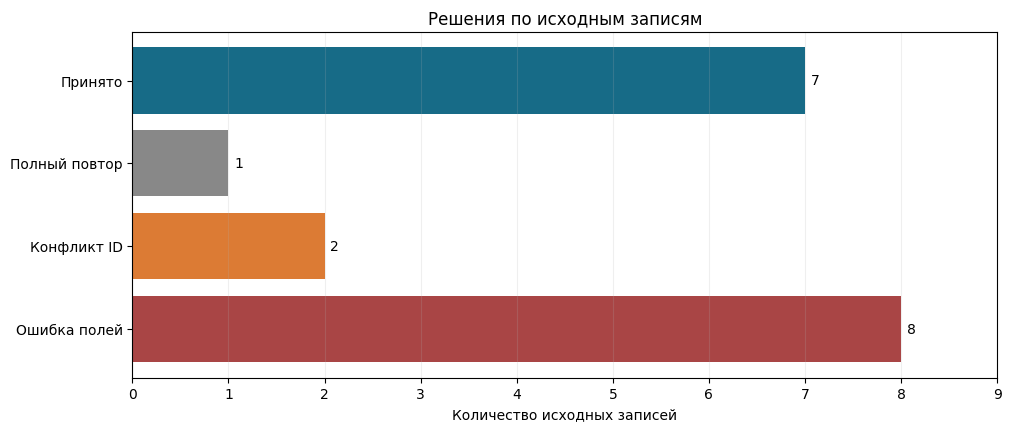

In [19]:
quality_figure, quality_axis = plt.subplots(figsize=(10, 4.2))
quality_bars = quality_axis.barh(
    decision_counts.index, decision_counts.to_numpy(),
    color=['#176B87', '#888888', '#DC7B34', '#A94545'],
)
quality_axis.bar_label(quality_bars, padding=4)
quality_axis.invert_yaxis()
quality_axis.set(
    title='Решения по исходным записям',
    xlabel='Количество исходных записей',
)
quality_axis.set_xticks(range(0, 10))
quality_axis.grid(axis='x', alpha=0.2)
plt.show()

**Разбор кода.**

- `plt.subplots(figsize=(10, 4.2))` создаёт рисунок и одну область. Два имени слева принимают два возвращённых объекта. Кортеж `figsize` задаёт ширину и высоту рисунка в дюймах.
- `decision_counts.index` содержит подписи решений, `.to_numpy()` — их количества в том же порядке. Метод `.barh(...)` строит горизонтальные столбцы. Список `color` задаёт цвета по порядку четырёх категорий.
- Возвращённые объекты столбцов сохраняются в `quality_bars`. `.bar_label(..., padding=4)` добавляет числа с небольшим отступом от края. Это текстовое оформление уже построенных столбцов.
- `.invert_yaxis()` показывает первую категорию сверху. `.set(...)` задаёт заголовок и подпись горизонтальной шкалы; изменения относятся к рисунку, не к таблице.
- `.set_xticks(range(0, 10))` задаёт целые деления от 0 до 9: `range` не включает свою правую границу. Для текущих значений шкала охватывает все столбцы.
- `.grid(axis='x', alpha=0.2)` добавляет лёгкую сетку по горизонтальной шкале. `alpha` задаёт прозрачность. `plt.show()` выводит рисунок под ячейкой.

Столбец «Принято» не означает, что остальные записи были исправлены. График различает пригодный набор, разрешённый повтор и записи, которым нужен разбор.

### 4.2. Состав только принятого набора

Следующий вопрос — какие виды и состояния представлены в данных, допущенных к дальнейшей работе. Здесь используются только строки окончательной таблицы. Поэтому числа отличаются от обзора всей исходной выгрузки.

Порядок категорий задаётся осознанно, а не получается случайно из текущей сортировки. Если разрешённая категория не встретилась, её счётчик может быть показан как ноль.

Этот блок подготавливает количества принятых записей по виду и статусу, затем показывает их рядом на одном рисунке. Названия видов берутся из справочника, порядок статусов — из правил журнала. Общий заголовок указывает, что отображается только принятый набор.

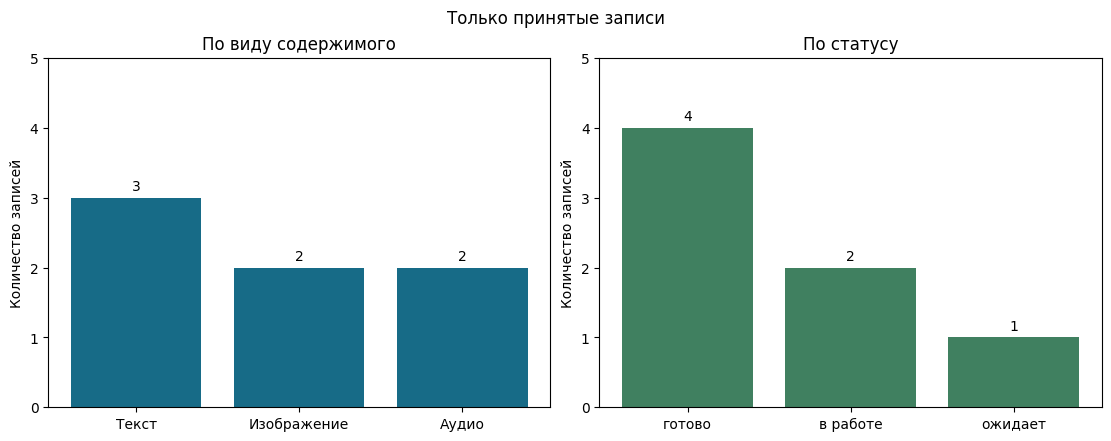

In [20]:
kind_order = kind_reference['kind_clean'].drop_duplicates().tolist()
status_order = ['готово', 'в работе', 'ожидает']
clean_kind_counts = clean_data['kind'].value_counts().reindex(kind_order, fill_value=0)
clean_status_counts = clean_data['status'].value_counts().reindex(status_order, fill_value=0)

summary_figure, summary_axes = plt.subplots(1, 2, figsize=(11, 4.3))
kind_bars = summary_axes[0].bar(clean_kind_counts.index, clean_kind_counts.to_numpy(), color='#176B87')
status_bars = summary_axes[1].bar(clean_status_counts.index, clean_status_counts.to_numpy(), color='#408060')
summary_axes[0].bar_label(kind_bars, padding=3)
summary_axes[1].bar_label(status_bars, padding=3)
summary_axes[0].set(title='По виду содержимого', ylabel='Количество записей')
summary_axes[1].set(title='По статусу', ylabel='Количество записей')
summary_axes[0].set_yticks(range(0, 6))
summary_axes[1].set_yticks(range(0, 6))
summary_figure.suptitle('Только принятые записи')
plt.show()

**Разбор кода.**

- `kind_reference['kind_clean']` выбирает согласованные названия из справочника. `.drop_duplicates()` оставляет первое появление каждого названия, `.tolist()` делает список порядка категорий.
- `status_order = [...]` задаёт другой список, явно перечисленный по правилам. Запятые разделяют текстовые значения, квадратные скобки создают список.
- `.value_counts()` считает записи окончательной таблицы, `.reindex(..., fill_value=0)` располагает результаты в выбранном порядке и добавляет нулевой счётчик отсутствующей разрешённой категории.
- `plt.subplots(1, 2, figsize=(11, 4.3))` создаёт одну строку из двух областей. В `summary_axes` находится коллекция областей: `[0]` выбирает левую, `[1]` — правую.
- Каждый `.bar(...)` получает подписи из `.index` и высоты из `.to_numpy()`. Сохранённые объекты столбцов передаются в `.bar_label(...)`, чтобы показать значения.
- Методы `.set(...)` задают заголовки и подписи выбранной области. `.set_yticks(range(0, 6))` включает деления от 0 до 5 на каждой вертикальной шкале.
- `.suptitle(...)` вызывается у `summary_figure`, поэтому относится ко всему рисунку. `plt.show()` показывает обе области одновременно.

В принятом наборе есть три текстовых запроса, два запроса изображений и два аудио. По состоянию это четыре готовых, два выполняющихся и один ожидающий. Нераспознанный вид не получил новую разрешённую категорию только ради включения в график.

### 4.3. Календарный порядок и смысл нулевого дня

Даты на рисунке располагаются по календарю, а не по алфавиту текстовых подписей. Для известного периода учебной выгрузки можно подготовить все семь дней и посчитать, сколько **принятых строк этого файла** относится к каждому.

Нулевой счётчик означает отсутствие принятых строк в этой выгрузке за соответствующий день. Он не доказывает, что в реальном сервисе не было запросов: часть исходных записей была отклонена, а сама выгрузка является учебной.

Следующий блок группирует принятую таблицу по дате создания и дополняет календарь днями известного периода. Затем он показывает счётчики и строит линию по настоящим значениям даты, явно подписывая каждое деление днём и месяцем.

2026-10-01    2
2026-10-02    2
2026-10-03    1
2026-10-04    0
2026-10-05    1
2026-10-06    1
2026-10-07    0
Freq: D, Name: Принятых записей из файла, dtype: int64

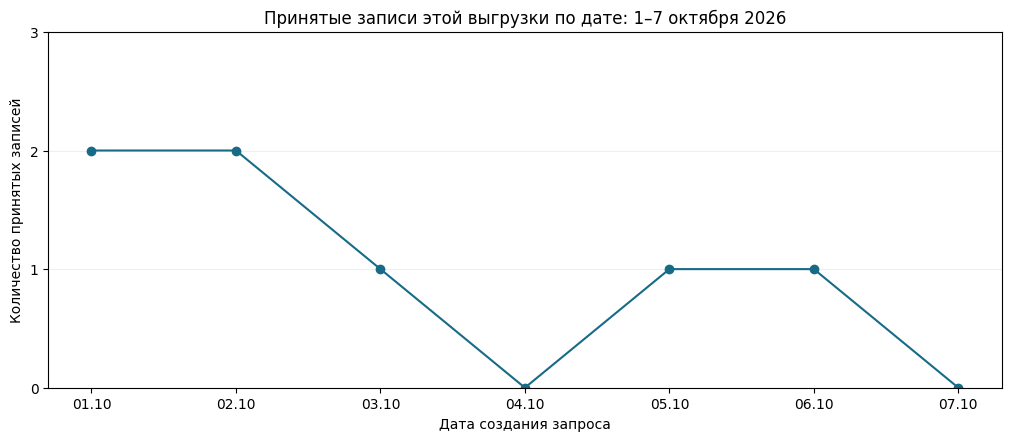

In [21]:
import matplotlib.dates as mdates

report_days = pd.date_range(period_start, period_end, freq='D')
daily_counts = clean_data.groupby('created_at').size().reindex(report_days, fill_value=0)
display(daily_counts.rename('Принятых записей из файла'))

daily_figure, daily_axis = plt.subplots(figsize=(10, 4.3))
daily_axis.plot(daily_counts.index, daily_counts.to_numpy(), marker='o', color='#176B87')
daily_axis.set(
    title='Принятые записи этой выгрузки по дате: 1–7 октября 2026',
    xlabel='Дата создания запроса', ylabel='Количество принятых записей',
)
daily_axis.set_xticks(report_days)
daily_axis.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
daily_axis.set_ylim(bottom=0)
daily_axis.set_yticks(range(0, 4))
daily_axis.grid(axis='y', alpha=0.2)
plt.show()

**Разбор кода.**

- `import matplotlib.dates as mdates` подключает средства оформления календарной оси и даёт им короткое имя. Это часть уже установленной Matplotlib.
- `pd.date_range(period_start, period_end, freq='D')` создаёт последовательность дней, включая обе заданные границы. Строка `'D'` задаёт ежедневный шаг; `report_days` хранит календарный индекс.
- `.groupby('created_at')` собирает строки одинаковой даты в группы, `.size()` возвращает количество строк каждой группы. Это число записей, а не длительность обработки и не количество файлов внутри запросов.
- `.reindex(report_days, fill_value=0)` дополняет результат всеми днями известного периода. Отсутствующие категории-даты получают нулевые счётчики. `display(... .rename(...))` показывает подготовленные данные до рисунка.
- `plt.subplots(...)` создаёт рисунок и область. В `.plot(...)` первый аргумент — индекс настоящих дат, второй — массив счётчиков, полученный методом `.to_numpy()`. `marker='o'` выделяет точки, `color` выбирает цвет линии.
- `.set_xticks(report_days)` ставит деления на всех семи днях. `daily_axis.xaxis` — объект горизонтальной оси, `.set_major_formatter(...)` задаёт оформление её основных подписей.
- `mdates.DateFormatter('%d.%m')` создаёт форматировщик: `%d` выводит день, `%m` — месяц. Значения дат не превращаются в текст в исходной таблице; меняется только их показ на рисунке.
- `.set_ylim(bottom=0)` задаёт нижнюю границу вертикальной шкалы. `.set_yticks(range(0, 4))` выбирает целые деления 0–3. `.grid(...)` добавляет полупрозрачную сетку, `.set(...)` — заголовок и подписи, `plt.show()` — итоговый вывод.

За 4 и 7 октября нет принятых строк: в исходнике за эти дни были проблемные записи. Линия соединяет ежедневные счётчики данного набора и не является прогнозом работы сервиса.

<a id="export"></a>
## 5. Сохранение и повторная загрузка

### 5.1. Данные, отчёт и материал для разбора

Очищенный набор и отклонённые записи решают разные задачи, поэтому сохраняются раздельно. Единый отчёт связывает их с исходными номерами, а файл полных повторов фиксирует автоматически разрешённое исключение.

CSV хранит значения, но не всё описание типов DataFrame. При дальнейшей загрузке нужно снова указать правила идентификаторов, дат и пропусков. Формат записи результата поэтому задаётся явно.

Следующий блок сохраняет четыре небольшие таблицы в папку результатов: принятый набор, записи для разбора, решения по всем исходным записям и полные повторы. Даты записываются в однозначном формате год-месяц-день, допустимое отсутствующее время — пустым полем. Повторный запуск обновляет эти четыре учебных файла.

In [22]:
export_tables = {
    'очищенные_запросы.csv': clean_data,
    'на_разбор.csv': review_data,
    'решения_по_записям.csv': audit,
    'полные_повторы.csv': exact_duplicates,
}
for file_name, table in export_tables.items():
    output_path = result_dir / file_name
    table.to_csv(
        output_path, sep=';', index=False, encoding='utf-8-sig',
        date_format='%Y-%m-%d', na_rep='',
    )
    print(file_name, '— записей:', len(table))

clean_path = result_dir / 'очищенные_запросы.csv'

очищенные_запросы.csv — записей: 7
на_разбор.csv — записей: 10
решения_по_записям.csv — записей: 18
полные_повторы.csv — записей: 1


**Разбор кода.**

- `export_tables = {...}` создаёт словарь: ключ — имя выходного файла, значение — уже готовая таблица. Таблицы передаются как объекты без кавычек, имена файлов — как строки в кавычках.
- `.items()` возвращает пары ключа и значения. В `for file_name, table in ...:` пара распаковывается в два имени. Строки с отступом повторяются для каждой таблицы.
- `result_dir / file_name` создаёт путь внутри выбранной папки. Оператор `/` у `Path` соединяет части пути. Получившийся `output_path` используется только для текущего прохода цикла.
- `.to_csv(...)` — метод записи DataFrame. Первый аргумент — путь, `sep=';'` — разделитель. `index=False` не добавляет в файл левый индекс Pandas; служебный `source_row` в отчётах сохранится, поскольку это обычный явный столбец.
- `encoding='utf-8-sig'` задаёт кодировку CSV. `date_format='%Y-%m-%d'` оформляет значения типа даты как год, месяц, день с дефисами. Исходные текстовые даты в таблице разбора остаются исходным текстом.
- `na_rep=''` записывает пропуск пустым полем, а не текстом `<NA>` и не нулём. Числовые дроби в этих выходных CSV используют точку — стандартную настройку записи Pandas.
- Если текст комментария содержит разделитель, `.to_csv(...)` сам добавляет нужные CSV-кавычки. Ручное удаление точек с запятой из комментария не требуется.
- `print(...)` выводит имя файла и число его строк; `len(table)` вычисляется для текущей таблицы. После окончания отступа `clean_path` сохраняет отдельный путь принятого набора для повторного чтения.

В файл для разбора попадают исходные значения с причинами. В принятый набор — преобразованные значения и согласованные названия. Это разные выходные данные одного процесса.

Этот блок сохраняет три уже построенных рисунка рядом с таблицами результатов. Для каждого рисунка задано отдельное имя PNG. Сохраняется объект Figure целиком, включая его области, заголовки и подписи.

In [23]:
figures_to_save = {
    'решения.png': quality_figure,
    'состав_принятого_набора.png': summary_figure,
    'принятые_записи_по_датам.png': daily_figure,
}
for file_name, figure in figures_to_save.items():
    image_path = result_dir / file_name
    figure.savefig(image_path, dpi=140, bbox_inches='tight')
    print('Сохранён рисунок:', image_path.name)

Сохранён рисунок: решения.png
Сохранён рисунок: состав_принятого_набора.png
Сохранён рисунок: принятые_записи_по_датам.png


**Разбор кода.**

- Словарь `figures_to_save` связывает текстовые имена файлов с объектами рисунков из предыдущих ячеек. Фигурные скобки создают словарь, двоеточие отделяет ключ от значения.
- В цикле `for file_name, figure in ... .items():` очередная пара распаковывается в имя файла и сам рисунок. Подчёркивания в переменных — части имён, пробелы в них не допускаются.
- `result_dir / file_name` создаёт путь PNG в папке результатов. Его расширение `.png` позволяет методу определить формат изображения.
- `figure.savefig(...)` записывает рисунок в файл. `dpi=140` задаёт разрешение, `bbox_inches='tight'` подбирает границы вокруг содержимого. Они влияют на изображение, но не меняют данные таблиц.
- Рисунок сохраняется из своего объекта, хотя уже был показан через `plt.show()`. Строить его заново не нужно, пока объект доступен под сохранённым именем.
- `.name` читает имя файла из объекта пути. `print(...)` показывает ход записи трёх изображений.

Те же рисунки встроены в ноутбук для чтения без запуска. Отдельные PNG подходят для использования рядом с отчётом по данным.

### 5.2. Проверка сохранённого результата

Успешная запись файла ещё не гарантирует, что при чтении сохранился нужный смысл. Идентификатор может потерять ведущие нули, дата — остаться текстом, а допустимый пропуск — стать обычной строкой.

Поэтому принятый набор читается обратно по явной схеме. Пропуск распознаётся только в разрешённом числовом поле, а текстовые поля сохраняются как текст. Затем сравниваются таблицы до и после записи.

Последний блок повторно читает сохранённый CSV с типами полей, форматом даты и правилом пропуска времени. Он проверяет совпадение с таблицей перед записью и выводит восстановленные данные и идентификаторы. Это завершает пример проверяемым результатом на диске.

In [24]:
reloaded = pd.read_csv(
    clean_path,
    sep=';', encoding='utf-8-sig',
    dtype={
        'request_id': 'string', 'kind': 'string', 'status': 'string',
        'file_count': 'Int64', 'elapsed_seconds': 'Float64', 'note': 'string',
    },
    parse_dates=['created_at'], date_format='%Y-%m-%d',
    keep_default_na=False, na_values={'elapsed_seconds': ['']},
)
assert clean_data.equals(reloaded), 'Содержимое или типы изменились после записи'
display(reloaded)
print('Идентификаторы:', reloaded['request_id'].tolist())
print('Повторное чтение подтвердило результат:', len(reloaded), 'записей.')

,request_id,created_at,kind,status,file_count,elapsed_seconds,note
0,001,2026-10-01,Текст,готово,1,2.5,Первый запрос
1,002,2026-10-01,Изображение,готово,3,6.0,Без комментария
2,003,2026-10-02,Аудио,в работе,2,<NA>,Запущено
3,004,2026-10-02,Текст,ожидает,1,<NA>,Без комментария
4,005,2026-10-03,Изображение,готово,4,8.2,Проверено; вручную
5,011,2026-10-05,Аудио,готово,2,4.7,Без комментария
6,013,2026-10-06,Текст,в работе,3,<NA>,Без комментария


Идентификаторы: ['001', '002', '003', '004', '005', '011', '013']
Повторное чтение подтвердило результат: 7 записей.


**Разбор кода.**

- `pd.read_csv(clean_path, ...)` читает именно сохранённый файл. `sep` и `encoding` соответствуют настройкам записи.
- Словарь `dtype` задаёт строковые и числовые типы по именам полей. `request_id` остаётся `'string'`, поэтому код 001 не превращается в 1. Типы `'Int64'` и `'Float64'` поддерживают пропуски Pandas.
- `parse_dates=['created_at']` указывает столбец для преобразования в дату. `date_format='%Y-%m-%d'` совпадает с форматом экспорта. Список содержит одно имя и всё равно остаётся списком.
- `keep_default_na=False` отключает общий список текстовых обозначений пропуска. `na_values={'elapsed_seconds': ['']}` задаёт конкретное исключение: пустая строка в поле времени должна быть пропуском. Например, текст `NA` в комментарии не был бы автоматически потерян.
- `clean_data.equals(reloaded)` возвращает одно логическое значение, сравнивая форму, подписи, значения и соответствующие типы столбцов двух таблиц. `assert ...` требует успешного совпадения; иначе выполнение останавливается с пояснением.
- `display(reloaded)` показывает восстановленную таблицу. `.tolist()` переводит идентификаторы в обычный список для вывода через `print(...)`. В последнем сообщении `len(reloaded)` сообщает число записей.

Сохранены ведущие нули идентификаторов, тип даты, согласованные категории и допустимые пропуски времени. Исходный журнал, отчёт по решениям и материал для разбора остаются рядом, поэтому результат можно проверить не только по итоговому графику.